# Zenodo 1,053: synthetic ground truth for z-neighbourhoods (2026-10-24)

Follows [`zenodo_1053_neighbourhoods_261024`](zenodo_1053_neighbourhoods_261024.ipynb). That notebook found cross-source, size-heterogeneous neighbourhoods (Kuramoto–Sakaguchi with Van der Pol; mouse fMRI with market log-returns; trending series with Brownian motion) and read them as shared forms of dependence. Real recordings have no known coupling, so that reading cannot be checked on them. The synthetic recordings can be checked, because their generating equations are published. The question here: among the 487 synthetic recordings, does z-proximity follow the generators' coupling form more than generator identity or recording size?

**Ground truth.** The archive's generators are described in Cliff et al. (2023), Supplementary Sec. S2 ([arXiv:2201.11941v2](https://arxiv.org/abs/2201.11941)). This repo's `src/mtsspi/generators/` did not produce these recordings and is not used. Descriptors and classes are declared in `configs/analysis/zenodo-ground-truth-261024.yaml`, committed (`7c9118b`) before any z result was computed; later edits to that file touch only a comment. Everything below is computed by `research/zenodo/atlas/ground_truth.py` from the cached PCA50 scores of `tsne-261021`; pyspi is not run.

**Units of evidence.** 487 recordings, 142 parent recordings, 17 generator families and 19 generator units. A unit is a family split by whether its coupling is present (VAR and VMA each have coupled and uncoupled configurations). Class is an attribute of units, so the effective sample size for "does class organise z" is 19 units, not 487 recordings. Windows of one parent are never treated as replicates.

**Summary** (numbers from the tables below; ± is a delete-one-parent jackknife 95% interval):
- Coupling class explains a real but partial share of z. Coarse classes explain 26% ± 7% (adjusted R²) of PCA50 variance among synthetic recordings, generator family 41% ± 9%, size 2.5% ± 1.2%, and parent recording 70% ± 5%; the last is the ceiling for any generator-level label. The a priori grouping of the 19 units into 8 classes explains more than random groupings of the same units into classes of the same sizes: partial R² beyond size .253 against a null median of .170 (p = .008). Finer coupling-function classes do better: .320 against .243 (p = .006).
- Generator identity matters beyond class. Family adds 15% ± 7% beyond coarse class and size, and 8.5% ± 5% beyond fine class (p ≤ .001).
- The one within-generator coupling contrast the archive offers is not detected. Coupled and uncoupled VAR and VMA configurations (10% coupling density) are not separated beyond size: partial R² .005 against .002 (p = .11).
- Nearest neighbours. 54% of recordings' nearest other-parent neighbour is from the same family. 16% [10, 21] is from another family of the same coarse class: 2.6× the rate when class labels are shuffled across units (p = .005) and 1.6× when shuffled across parents within size strata (p = .009). The excess survives restricting neighbours to the same size stratum at k = 1. At k = 5 within size strata it survives only the unit null.
- Two cross-family unit pairs are enriched (q ≤ .05, 171 pairs): Kuramoto–Sakaguchi with Kuramoto sync, and coupled VAR with coupled VMA. Both pairs share coarse and fine class. No FDR-significant cross-family pair crosses a class. Same-class pairs are not uniformly near: CML–TestWEATH and TestCLIM–coupled VAR/VMA are depleted.
- Toolbox confound. Given toolbox and size, the a priori classes are no better than random groupings (p = .41 coarse; .055 fine). The toolboxes are Brain Dynamics Toolbox, pyclustering, the archive authors' code, CauseMe and NetSim. The archive confounds coupling form with simulation software, solver, sampling and size grid, and this design cannot separate them.
- The motivating pair. Kuramoto–Sakaguchi and Van der Pol share the coarse class (oscillator) but not the coupling function (phase difference versus position forcing). By size-matched distance, Kuramoto–Sakaguchi is nearer Van der Pol (.70) and the uncoupled Ornstein–Uhlenbeck process (.76), both run in the same toolbox, than Kuramoto sync (1.01), which has its coupling function. Within Kuramoto sync, neighbours follow the sampled observable rather than K or the coupling equation: 9 of the 15 windows of the two smooth settings neighbour Kuramoto–Sakaguchi, and none of the near-white aliased settings do; those neighbour noise, linear processes and each other.
- Reading: z tracks the dependence organisation of the observed series. The coupling in the equations predicts it where the observation expresses that coupling, and sampling, coupling density and toolbox conventions can override it. Co-location is evidence of a shared observable dependence organisation. It is weaker evidence of a shared generating mechanism: it holds above chance at the class level and does not survive the toolbox control.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.spatial.distance import pdist, squareform
from threadpoolctl import threadpool_limits
from research.zenodo.atlas import ground_truth as gt
from research.zenodo.atlas import tsne_atlas as ta
%matplotlib inline

ta.notebook_style()
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)
config = yaml.safe_load(gt.CONFIG.read_text())
OUT = ROOT / config["output"]
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
if not (OUT / "manifest.json").exists():
    with threadpool_limits(limits=config["threads"]):
        gt.compute(config, OUT)  # about 3 minutes on 8 cores
G = gt.load(OUT)
frame, units = G["descriptors"], G["units"]
COARSE = ["uncoupled-white", "uncoupled-serial", "uncoupled-trending", "linear-lagged", "linear-instantaneous",
          "nonlinear-lagged", "oscillator", "wave-field"]
FINE = COARSE[:6] + ["phase-difference", "position-forcing", "relaxation", "sigmoid-rate", "wave-field"]
order = units.assign(c=units.coarse.map(COARSE.index), f=units.fine.map(FINE.index)).sort_values(["c", "f", "source"]).index.tolist()
print(f"{len(frame)} synthetic recordings, {frame.parent.nunique()} parent recordings, {frame.source.nunique()} generator families, "
      f"{len(units)} generator units (family × coupling present)")

487 synthetic recordings, 142 parent recordings, 17 generator families, 19 generator units (family × coupling present)


## 1. Ground truth from the generator equations

Each synthetic dataset name is matched to a rule in the config, and each rule records where its descriptor comes from. Classes describe the coupling term of the generating equations. They do not describe emergent behaviour, because emergent behaviour is not fixed by the equations. For example, for two Kuramoto–Sakaguchi oscillators the phase difference obeys dφ/dt = Δω − 2K cos α sin φ, so the frustration α only rescales the coupling; whether a locked state is phase-lagged depends on Δω. "Phase-lagged oscillation" therefore cannot be assigned a priori, and no class uses it.

| coarse class | a priori definition | generator units |
|---|---|---|
| uncoupled-white | no coupling, no serial dependence | IID noise |
| uncoupled-serial | no coupling, stationary serial dependence | VAR and VMA uncoupled, Ornstein–Uhlenbeck |
| uncoupled-trending | no coupling, integrated with a common drift | Brownian motion (arithmetic, geometric) |
| linear-lagged | linear coupling at lags of one sample or more | VAR and VMA coupled, TestCLIM |
| linear-instantaneous | linear coupling at lags far below the sampling interval | NetSim |
| nonlinear-lagged | nonlinear coupling at lags of one sample or more | CML, TestWEATH |
| oscillator | coupled oscillator networks (S2.3.2) | Kuramoto–Sakaguchi, Kuramoto sync, Van der Pol, LEGION, hysteresis, Wilson–Cowan |
| wave-field | linear wave equation; spatially local coupling with propagation lags | Wave 1D, Wave 2D |

The fine scheme splits the oscillators by coupling function:
- *phase-difference*: Kuramoto–Sakaguchi and Kuramoto sync, K sin(θ_j − θ_i − α) with α = 1 rad or 0;
- *position-forcing*: Van der Pol;
- *relaxation*: LEGION and hysteresis;
- *sigmoid-rate*: Wilson–Cowan.

Two classes contain a single unit: uncoupled-white and linear-instantaneous. Uncoupled-trending contains a single family. These classes count toward variance explained, but they can never supply a cross-family same-class neighbour.

**Could not be recovered**, and kept as caveats rather than guessed:
- the CauseMe equations, coefficients and form of nonstationarity (TestCLIM, TestWEATH). TestWEATHmiss is absent from S2 and codes missing values as 999.0;
- NetSim's per-simulation settings. NetSim is not described in S2 and is identified from its names (sim1–sim28) and tags as Smith et al. (2011);
- the VAR/VMA innovation covariance, so zero-lag innovation coupling cannot be excluded;
- the Van der Pol coupling index (S2 eq. 9 as printed sums a_ij z_i) and its μ, ν;
- oscillator frequency distributions, solver steps, the Kuramoto–Sakaguchi K, and the LEGION and hysteresis observables;
- whether the Wilson–Cowan parameters give a limit cycle.

In [2]:
cols = ["source", "toolbox", "coupling", "interaction", "lag", "observable", "coarse", "fine"]
table = frame.groupby("unit")[cols].first().join(units[["parents", "recordings"]]).loc[order]
table

,source,toolbox,coupling,interaction,lag,observable,coarse,fine,parents,recordings
unit,,,,,,,,,,
IID noise,IID noise,NumPy,none,none,none,samples,uncoupled-white,uncoupled-white,5,56
Ornstein–Uhlenbeck,Ornstein–Uhlenbeck,Brain Dynamics Toolbox,none,none (M independent SDEs),none,state,uncoupled-serial,uncoupled-serial,1,9
VAR uncoupled,VAR,authors' code,none,none (diagonal Phi),none,state,uncoupled-serial,uncoupled-serial,2,24
VMA uncoupled,VMA,authors' code,none,none (diagonal Theta),none,state,uncoupled-serial,uncoupled-serial,2,23
Brownian motion,Brownian motion,Brain Dynamics Toolbox,none,none (M independent SDEs),none,state,uncoupled-trending,uncoupled-trending,2,14
TestCLIM,TestCLIM,CauseMe (external),linear,"linear with time delays (CLIM), monthly aggregation; CLIMnoise add...","delays up to a couple of months (1-3 samples), blurred by aggregation",subsampled channels of a 40-process system,linear-lagged,linear-lagged,30,30
VAR coupled,VAR,authors' code,linear,"z_i,t <- Phi_ij z_j,t-1, 10% random directed density, symmetric or...",1 sample,state,linear-lagged,linear-lagged,4,43
VMA coupled,VMA,authors' code,linear,"z_i,t <- Theta_ij a_j,t-1, 10% random directed density",1 sample (shared lagged shocks also give zero-lag covariance),state,linear-lagged,linear-lagged,4,45
NetSim fMRI,NetSim fMRI,NetSim (external),linear,linear directed neural coupling (DCM) seen through balloon-model h...,neural delays far below the sampling interval for most simulations,simulated BOLD,linear-instantaneous,linear-instantaneous,23,24


In [3]:
frame.groupby("unit")[["evidence", "caveat"]].first().loc[order].fillna("")

,evidence,caveat
unit,,
IID noise,"S2.1.1 (normal, Cauchy, exponential, gamma, t2)",
Ornstein–Uhlenbeck,S2.1.2,theta not stated; the shared relaxation from z0 toward mu adds a c...
VAR uncoupled,S2.2 (coupling density 0 = independent),
VMA uncoupled,S2.2,
Brownian motion,S2.1.2,a shared deterministic drift makes independent channels co-trend (...
TestCLIM,"S2.4.4; archive tags (var, linear, time delay, time-aggregation); ...","exact CauseMe equations, coefficients and the form of the nonstati..."
VAR coupled,S2.2,"innovation covariance Sigma not stated, so zero-lag innovation cou..."
VMA coupled,S2.2,innovation covariance Sigma not stated
NetSim fMRI,not described in S2; recognised from the names sim1-sim28 and arch...,"per-simulation settings (TR, networks, confounds) taken as unverif..."


In [4]:
counts = (units.groupby(["coarse", "fine"])
          .agg(units=("source", "size"), families=("source", "nunique"), parents=("parents", "sum"), recordings=("recordings", "sum"),
               members=("source", lambda s: ", ".join(sorted(s.index))))
          .reset_index())
counts = counts.assign(c=counts.coarse.map(COARSE.index), f=counts.fine.map(FINE.index)).sort_values(["c", "f"]).drop(columns=["c", "f"])
counts.set_index(["coarse", "fine"])

units  families  parents  recordings                                           members
coarse               fine                                                                                                        
uncoupled-white      uncoupled-white           1         1        5          56                                         IID noise
uncoupled-serial     uncoupled-serial          3         3        5          56  Ornstein–Uhlenbeck, VAR uncoupled, VMA uncoupled
uncoupled-trending   uncoupled-trending        1         1        2          14                                   Brownian motion
linear-lagged        linear-lagged             3         3       38         118                TestCLIM, VAR coupled, VMA coupled
linear-instantaneous linear-instantaneous      1         1       23          24                                       NetSim fMRI
nonlinear-lagged     nonlinear-lagged          2         2       47          85                                    CML, TestWEATH
oscillator           phase-difference          2         2       11          96               Kuramoto–Sakaguchi, Oscillator sync
                     position-forcing          1         1        2           6                                       Van der Pol
                     relaxation                2         2        6          14                     LEGION, Oscillator hysteresis
                     sigmoid-rate              1         1        1           3                                      Wilson–Cowan
wave-field           wave-field                2         2        2          15                                  Wave 1D, Wave 2D

## 2. Descriptor checks on the raw series

These checks verify that the observable matches its description. They were not used to assign classes. Columns:
- `abs_ac1`: mean |lag-1 autocorrelation| over channels (VAR/VMA coefficient signs are random, so the signed mean is near 0);
- `trend_r2`: mean linear-trend R²;
- `abs_r0`: mean |zero-lag correlation| over channel pairs;
- `lagged_peak_share`: share of pairs whose largest |cross-correlation| within ±5 samples is at a non-zero lag.

What they show:
- Bounded outputs in [−1, 1] confirm the sin θ observable for both Kuramoto models.
- Brownian motion co-trends: trend R² about .6 and |r| about .55–.6 between independent channels, as the shared drift predicts.
- In most NetSim simulations most channel pairs peak at zero lag, consistent with neural delays below the sampling interval. Sims 19–20 are the exception: smooth (|ac1| .99) and mostly lagged.
- Coupled VAR and VMA are hardly distinguishable from uncoupled ones in raw correlation: |r0| is .036–.044, against .029–.034 uncoupled and .027 for IID noise. At 10% density there are about M(M − 1)/10 directed links.
- **Kuramoto sync is heterogeneous.** At K = ±20, and at K = 4 or on sparse graphs, |ac1| is .03–.25, so the sampled sin θ is close to white (inferred: the phase advances a large fraction of a cycle per sample). Only K = −1 and K = −4 all-to-all are smooth (|ac1| ≥ .84). The same coupling equation therefore yields very different observables.

In [5]:
raw = G["raw-checks"].merge(frame[["dataset", "unit", "parent", "M", "T"]], on="dataset")
checks = ["min", "max", "abs_ac1", "trend_r2", "abs_r0", "peak_abs_xcorr", "lagged_peak_share"]
raw.groupby("unit")[checks].median().loc[order].round(3)

,min,max,abs_ac1,trend_r2,abs_r0,peak_abs_xcorr,lagged_peak_share
unit,,,,,,,
IID noise,-3.802,12.324,0.028,0.001,0.027,0.072,0.916
Ornstein–Uhlenbeck,0.051,0.933,0.887,0.037,0.121,0.154,0.690
VAR uncoupled,-3.495,3.736,0.482,0.003,0.034,0.066,0.911
VMA uncoupled,-3.747,3.738,0.438,0.002,0.029,0.070,0.911
Brownian motion,0.590,13.369,0.988,0.601,0.590,0.595,0.619
TestCLIM,-2.715,2.735,0.281,0.014,0.156,0.218,0.841
VAR coupled,-3.678,3.581,0.270,0.003,0.044,0.090,0.900
VMA coupled,-3.719,3.636,0.247,0.001,0.036,0.092,0.911
NetSim fMRI,-9.876,7.854,0.377,0.000,0.247,0.247,0.000


In [6]:
pick = raw.unit.isin(["Oscillator sync", "NetSim fMRI", "TestCLIM", "TestWEATH", "CML"])
by_parent = raw[pick].assign(setting=lambda d: d.parent.str.replace(r"_S\d+$", "", regex=True))
by_parent.groupby(["unit", "setting"])[["abs_ac1", "trend_r2", "abs_r0", "lagged_peak_share", "max"]].median().round(3)

abs_ac1  trend_r2  abs_r0  lagged_peak_share      max
unit            setting                                                                                                           
CML             chaotic_brownian_motion_of_defect_alpha-1-85_epsilon-0-1       0.825     0.000   0.347              0.926    0.995
                defect_turbulence_alpha-1-895_epsilon-0-1                      0.752     0.000   0.140              0.900    0.997
                pattern_selection_alpha-1-71_epsilon-0-4                       0.826     0.003   0.484              0.644    0.999
                spatiotemporal_chaos_alpha-2-0_epsilon-0-3                     0.680     0.001   0.211              0.733    0.999
                spatiotemporal_intermittency_i_alpha-1-7522_epsilon-0-00115    0.444     0.056   0.118              0.926    1.000
                spatiotemporal_intermittency_ii_alpha-1-75_epsilon-0-3         0.844     0.002   0.325              0.830    0.998
                traveling_wave_alpha-1-67_epsilon-0-5                          0.448     0.091   0.511              0.546    0.992
NetSim fMRI     sim1                                                           0.349     0.000   0.241              0.000    7.984
                sim10                                                          0.421     0.000   0.382              0.000    9.465
                sim11                                                          0.365     0.000   0.228              0.089    6.650
                sim12                                                          0.356     0.000   0.126              0.356    6.358
                sim13                                                          0.351     0.000   0.110              0.100    8.924
                sim14                                                          0.351     0.000   0.278              0.000    7.917
                sim15                                                          0.433     0.000   0.619              0.000    7.676
                sim16                                                          0.340     0.000   0.330              0.000    8.731
                sim17                                                          0.451     0.000   0.160              0.311    6.367
                sim18                                                          0.353     0.000   0.249              0.000    7.271
                sim19                                                          0.993     0.000   0.318              0.800    6.656
                sim2                                                           0.357     0.000   0.134              0.333    8.021
                sim20                                                          0.993     0.000   0.318              0.700    7.526
                sim22                                                          0.466     0.000   0.225              0.200    6.418
                sim25                                                          0.352     0.000   0.258              0.000    7.792
                sim26                                                          0.322     0.000   0.242              0.100    7.538
                sim27                                                          0.411     0.000   0.304              0.000    6.166
                sim28                                                          0.438     0.000   0.315              0.000    6.329
                sim5                                                           0.395     0.000   0.245              0.000    7.928
                sim6                                                           0.389     0.000   0.135              0.378    8.080
                sim7                                                           0.391     0.000   0.198              0.100    8.249
                sim8                                                           0.349     0.000   0.380              0.000    8.154
                

## 3. Variance partitioning

**Method.** Distances are Euclidean in PCA50, so distance-based partitioning (PERMANOVA or db-RDA; McArdle & Anderson 2001) equals least-squares partitioning of the coordinates themselves. Three blocks are fitted:
- class: one-hot of the coarse or fine class;
- family: one-hot of the 17 generator families;
- size: a quadratic surface in (log M, log T), as in `mt_control`.

Fractions are Legendre's: [x] is unique to block x given the others, and [x·y] is shared. They use adjusted R² (Peres-Neto et al. 2006). Two weightings are shown:
- every recording weighs 1;
- every parent weighs 1, using Kish's effective n. This matters because the 93 single-window parents of TestCLIM, TestWEATH and NetSim are 65% of parents but 19% of recordings.

`R2adj parent` (142 levels) is the ceiling for any label that is constant within a parent.

**Uncertainty.** Intervals are ± 1.96 delete-one-parent jackknife standard errors. A parent bootstrap was tried first and rejected: resampling parents with replacement duplicates them, which shrinks the spread between parents of a family and inflates every between-parent fraction. Its percentile intervals sat above the estimates (family .408 [.406, .498]).

**Identification.** Family is nested in class except for VAR and VMA, which each span two classes. [class] given family is therefore identified only by the coupled and uncoupled VAR/VMA contrast. Whether class "explains beyond generator identity" has to be judged from [family] (what generator identity adds beyond class), from the unit-level null below, and from the cross-family neighbour tests in sections 4–5.

In [7]:
F = G["fractions"]
venn = ["[class]", "[family]", "[size]", "[class·family]", "[class·size]", "[family·size]", "[class·family·size]", "residual"]
margins = ["R2adj class", "R2adj family", "R2adj size", "R2adj parent", "[class | toolbox, size]"]
fmt = F.assign(cell=[f"{v:.3f} [{lo:.3f}, {hi:.3f}]" for v, lo, hi in zip(F.value, F.ci_low, F.ci_high)])
shown = fmt.pivot_table(index="fraction", columns=["scheme", "weighting"], values="cell", aggfunc="first").loc[margins + venn]
shown[[("coarse", "rows"), ("coarse", "parent"), ("fine", "rows"), ("fine", "parent")]]

scheme                                   coarse                                             fine                         
weighting                                  rows                   parent                    rows                   parent
fraction                                                                                                                 
R2adj class                0.258 [0.192, 0.324]     0.237 [0.179, 0.295]    0.321 [0.247, 0.395]     0.280 [0.219, 0.341]
R2adj family               0.408 [0.317, 0.499]     0.328 [0.262, 0.395]    0.408 [0.317, 0.499]     0.328 [0.262, 0.395]
R2adj size                 0.025 [0.012, 0.037]     0.071 [0.031, 0.111]    0.025 [0.012, 0.037]     0.071 [0.031, 0.111]
R2adj parent               0.696 [0.648, 0.745]     0.714 [0.663, 0.765]    0.696 [0.648, 0.745]     0.714 [0.663, 0.765]
[class | toolbox, size]    0.095 [0.049, 0.141]     0.029 [0.005, 0.054]    0.162 [0.094, 0.230]     0.079 [0.042, 0.116]
[class]                   0.004 [-0.001, 0.009]  -0.002 [-0.004, -0.001]   0.004 [-0.001, 0.009]  -0.002 [-0.004, -0.001]
[family]                   0.149 [0.082, 0.216]     0.083 [0.044, 0.123]    0.085 [0.036, 0.134]     0.036 [0.011, 0.061]
[size]                     0.008 [0.004, 0.011]    0.004 [-0.008, 0.017]    0.008 [0.004, 0.011]    0.004 [-0.008, 0.017]
[class·family]             0.241 [0.182, 0.301]     0.179 [0.139, 0.219]    0.305 [0.236, 0.375]     0.226 [0.177, 0.275]
[class·size]             -0.000 [-0.000, 0.000]    0.000 [-0.000, 0.000]  -0.000 [-0.000, 0.000]    0.000 [-0.000, 0.000]
[family·size]             0.005 [-0.001, 0.011]    0.006 [-0.000, 0.013]    0.006 [0.001, 0.012]     0.010 [0.002, 0.018]
[class·family·size]        0.013 [0.001, 0.024]     0.060 [0.020, 0.100]   0.011 [-0.002, 0.024]     0.056 [0.015, 0.098]
residual                   0.581 [0.490, 0.671]     0.669 [0.602, 0.737]    0.581 [0.490, 0.671]     0.669 [0.602, 0.737]

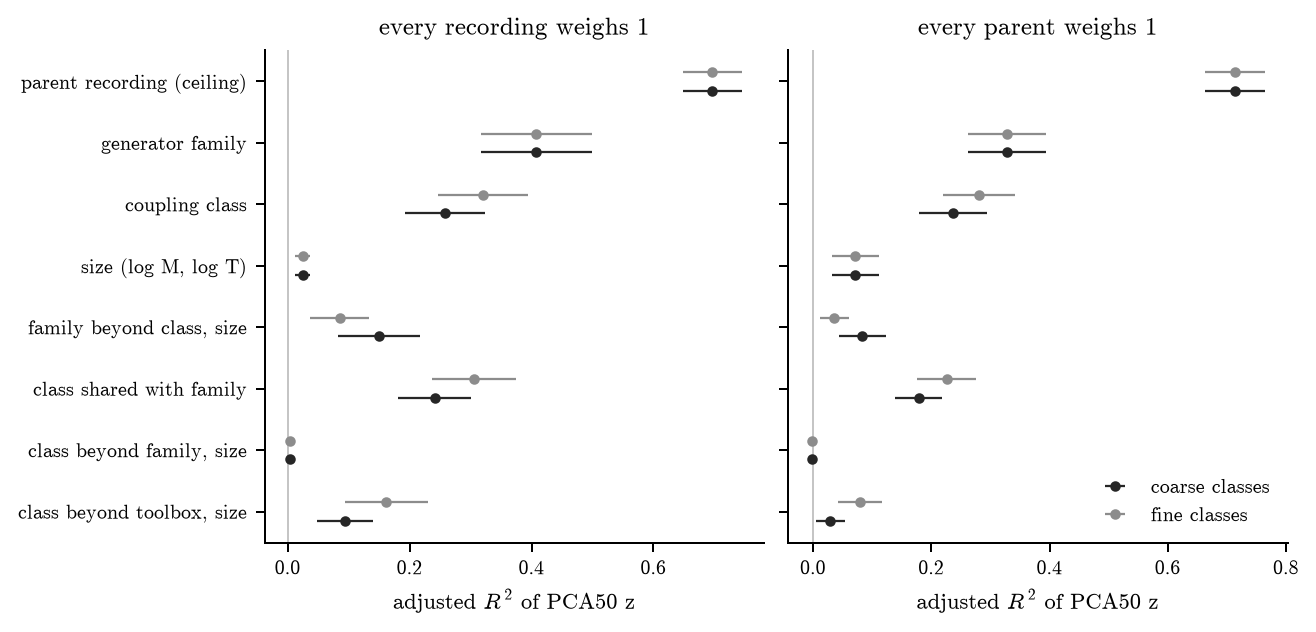

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4), sharey=True)
labels = {"R2adj parent": "parent recording (ceiling)", "R2adj family": "generator family", "R2adj class": "coupling class",
          "R2adj size": "size (log M, log T)", "[family]": "family beyond class, size", "[class·family]": "class shared with family",
          "[class]": "class beyond family, size", "[class | toolbox, size]": "class beyond toolbox, size"}
keys = list(labels)
for ax, weighting in zip(axes, ["rows", "parent"]):
    for offset, (scheme, colour) in zip((-.15, .15), [("coarse", "0.15"), ("fine", "0.55")]):
        d = F[(F.weighting == weighting) & (F.scheme == scheme)].set_index("fraction").loc[keys]
        y = np.arange(len(keys))[::-1] + offset
        ax.errorbar(d.value, y, xerr=[d.value - d.ci_low, d.ci_high - d.value], fmt="o", ms=3.2, color=colour,
                    elinewidth=.9, capsize=0, label=f"{scheme} classes")
    ax.axvline(0, color="0.7", lw=.6)
    ax.set(xlabel="adjusted $R^2$ of PCA50 z", title="every recording weighs 1" if weighting == "rows" else "every parent weighs 1")
axes[0].set_yticks(np.arange(len(keys))[::-1], [labels[k] for k in keys])
axes[1].legend(loc="lower right")
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIGURES / f"variance-fractions.{ext}", dpi=600 if ext == "png" else None)
plt.show()

**Reading.** Generator family is a coarsening of parent recording (41% of 70%), and coupling class is a coarsening of family: 26% coarse and 32% fine, almost all of it shared with family. Size explains little: 2.5% marginally, 1.3% within parents. That is less than in the full corpus (6%), because the synthetic grids cross sizes with generators. Parent weighting lowers family and class and raises size to 7%, because single-window parents vary in M without replication.

### Tests and their nulls

Each test is a pseudo-F for a block after the given blocks, against permutations that respect the parent structure (5,000 each). `partial_r2` is the block's sum of squares after the given blocks as a share of the total; the null columns give its permutation distribution.
- **class | size, labels across units.** This is the key test: is the a priori grouping of the 19 units into classes better than random groupings of the same units into classes of the same sizes? Units stay intact, so their cohesion helps the null as much as the observation.
- **class | size, labels across parents within size strata.** This is the parent-level null the brief asked for. It breaks units apart and spreads each class over parents of similar size. Units are cohesive, so this null is easier to beat; here its expected value is lower than the unit null's.
- **class | toolbox + size.** The same as the key test, after toolbox.
- **class | family + size.** Class labels move among parents within a family, so only VAR and VMA vary; 225 distinct arrangements.
- **family | class + size.** Family labels move among parents within a class.
- **size | ….** (M, T) labels move among the windows of each parent.

In [9]:
T = G["tests"]
T["test"] = T.effect + " | " + T.given
T[["scheme", "weighting", "test", "null", "partial_r2", "null_partial_r2_median", "null_partial_r2_q975", "F", "null_F_median", "p"]].round(4)

,scheme,weighting,test,null,partial_r2,null_partial_r2_median,null_partial_r2_q975,F,null_F_median,p
0,coarse,rows,class | size,class labels permuted across generator units,0.2534,0.1702,0.2382,24.1087,14.4946,0.0082
1,coarse,rows,class | size,class labels permuted across parents within size strata,0.2534,0.1109,0.1434,24.1087,8.7909,0.0002
2,coarse,rows,class | toolbox + size,class labels permuted across generator units,0.0999,0.1208,0.1663,14.0893,13.2689,0.4061
3,coarse,rows,class | family + size,class labels permuted across parents within family,0.0053,0.0022,0.0063,4.4306,1.8045,0.1084
4,coarse,rows,family | class + size,family labels permuted across parents within class,0.1576,0.0969,0.1303,13.1887,7.3083,0.0004
5,coarse,rows,size | class + family,"(M, T) permuted across windows within parent",0.0132,0.0042,0.0056,2.2145,0.6885,0.0002
6,coarse,rows,size | parent,"(M, T) permuted across windows within parent",0.0128,0.0030,0.0041,4.2809,0.9618,0.0002
7,coarse,parent,class | size,class labels permuted across generator units,0.1988,0.1500,0.2097,7.4008,5.2247,0.0612
8,coarse,parent,class | size,class labels permuted across parents within size strata,0.1988,0.0735,0.0993,7.4008,2.3244,0.0002
9,coarse,parent,class | toolbox + size,class labels permuted across generator units,0.0467,0.0845,0.1087,2.4638,3.5461,0.8514


**Reading.** Under the unit null, coupling class beats random groupings of the same generators: p = .008 coarse and .006 fine, or .06 and .012 with parent weighting. Generator identity adds beyond class (p ≤ .001). Size has a small but certain within-parent effect, the precision effect of M. The toolbox control removes the class advantage (coarse p = .41, fine p = .055). This control over-adjusts, because toolbox is itself partly aligned with class: pyclustering runs only oscillators and NetSim only one class. But it means the archive cannot separate coupling form from simulation software and sampling conventions. The within-family coupling contrast (p = .11) is underpowered (2 against 4 parents in each of VAR and VMA) as well as weak in the raw series (section 2).

### Leave one family out

Dropping each family in turn shows whether one generator carries a fraction. Removing Kuramoto sync raises class R² most (coarse .26 → .35), because sync's aliased settings do not sit with the other oscillators. No single family carries the class advantage.

In [10]:
L = G["lofo"]
keys = ["R2adj class", "R2adj family", "R2adj size", "[class]", "[family]", "[class·family]", "[class | toolbox, size]"]
full = F[F.weighting == "rows"].pivot_table(index="scheme", columns="fraction", values="value")
rows = []
for scheme, d in L.groupby("scheme"):
    for k in keys:
        delta = d[k] - full.loc[scheme, k]
        i = delta.abs().idxmax()
        rows.append({"scheme": scheme, "quantity": k, "all families": full.loc[scheme, k], "min": d[k].min(), "max": d[k].max(),
                     "largest move when dropping": d.loc[i, "dropped"], "change": delta[i]})
pd.DataFrame(rows).round(3)

,scheme,quantity,all families,min,max,largest move when dropping,change
0,coarse,R2adj class,0.258,0.214,0.352,Oscillator sync,0.094
1,coarse,R2adj family,0.408,0.377,0.476,Oscillator sync,0.068
2,coarse,R2adj size,0.025,0.021,0.032,TestCLIM,0.008
3,coarse,[class],0.004,0.002,0.006,VAR,-0.003
4,coarse,[family],0.149,0.102,0.163,LEGION,-0.048
5,coarse,[class·family],0.241,0.196,0.328,Oscillator sync,0.087
6,coarse,"[class | toolbox, size]",0.095,0.073,0.121,Oscillator sync,0.026
7,fine,R2adj class,0.321,0.282,0.400,Oscillator sync,0.080
8,fine,R2adj family,0.408,0.377,0.476,Oscillator sync,0.068
9,fine,R2adj size,0.025,0.021,0.032,TestCLIM,0.008


## 4. Size-matched distances between generator units

This compares units only where they share a size stratum. Strata are M ∈ {≤ 7, 8–13, ≥ 14} × T ∈ {≤ 300, ≤ 750, ≤ 1,500, > 1,500}, which pairs each grid value with its counterpart in the other grid. Within a stratum, other-parent distances are divided by that stratum's median, because z is noisier at small M; strata are then averaged with equal weight.

`proximity` is a single cross-generator statistic computed over unit pairs of different families: 1 − (mean same-class distance) / (mean other-class distance). It is compared against class labels permuted across units.

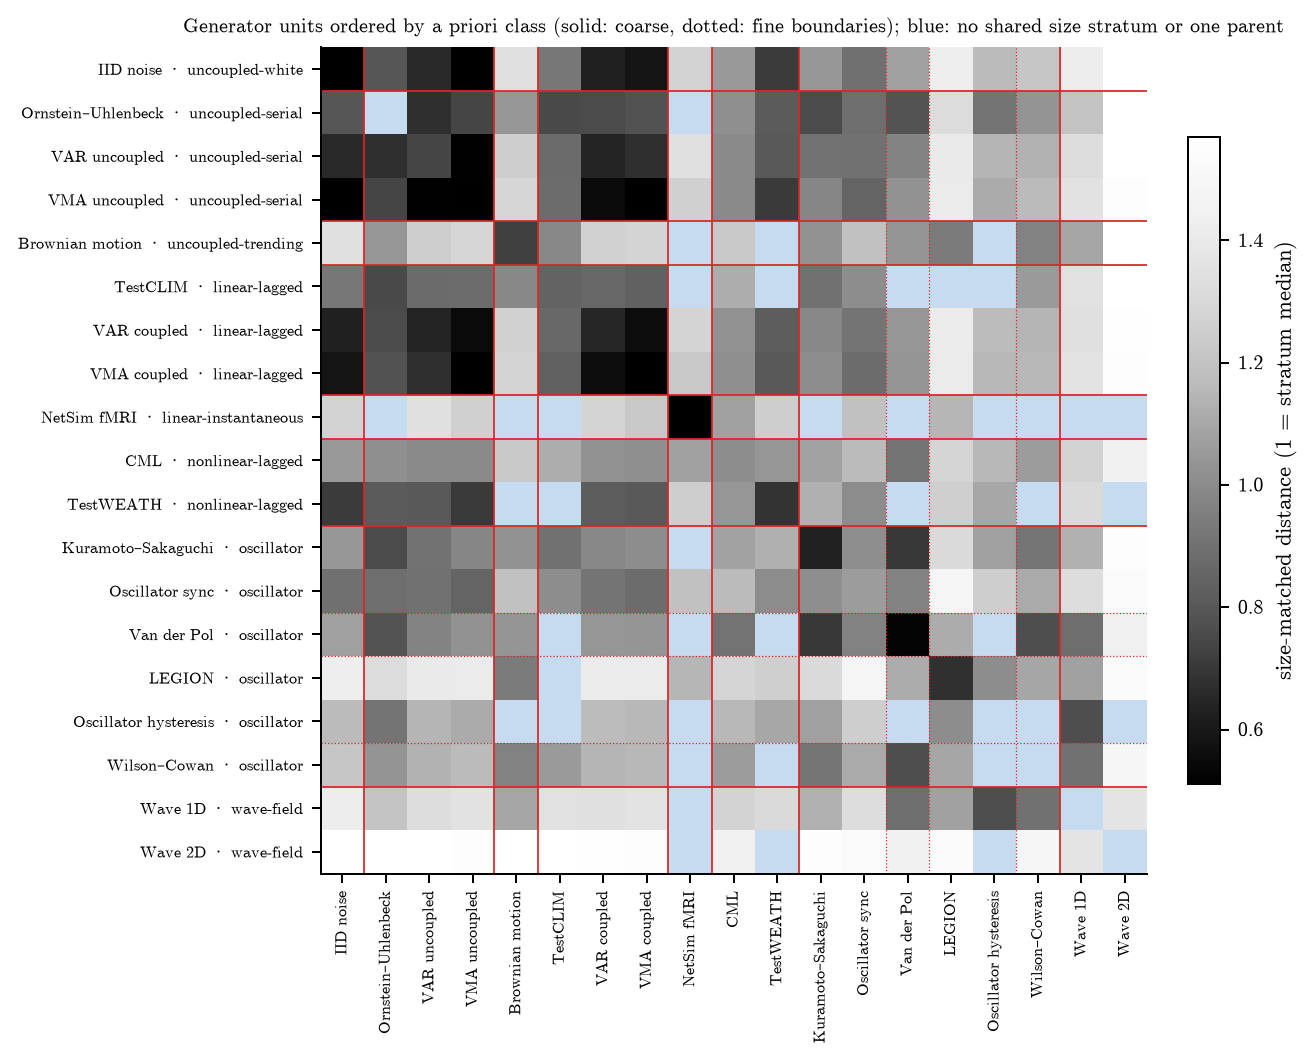

In [11]:
U = G["unit-distances"]
mat = pd.DataFrame(np.nan, index=order, columns=order)
for r in U.itertuples():
    mat.loc[r.unit_a, r.unit_b] = mat.loc[r.unit_b, r.unit_a] = r.distance
fig, ax = plt.subplots(figsize=(7.2, 6.4))
cmap = plt.get_cmap("Greys_r").copy()
cmap.set_bad("#c6dbef")
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy()), cmap=cmap, vmin=np.nanpercentile(mat.to_numpy(), 2), vmax=np.nanpercentile(mat.to_numpy(), 98))
cls = units.loc[order, "coarse"].to_numpy()
edges = [i + .5 for i in range(len(order) - 1) if cls[i] != cls[i + 1]]
for e in edges:
    ax.axhline(e, color="tab:red", lw=.7)
    ax.axvline(e, color="tab:red", lw=.7)
fine = units.loc[order, "fine"].to_numpy()
for i in range(len(order) - 1):
    if fine[i] != fine[i + 1] and cls[i] == cls[i + 1]:
        ax.axhline(i + .5, color="tab:red", lw=.5, ls=":")
        ax.axvline(i + .5, color="tab:red", lw=.5, ls=":")
tick = [f"{u}  ·  {units.loc[u, 'coarse']}" for u in order]
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(order)), tick, fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=.6, label="size-matched distance (1 = stratum median)")
ax.set_title("Generator units ordered by a priori class (solid: coarse, dotted: fine boundaries); blue: no shared size stratum or one parent", fontsize=8)
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIGURES / f"unit-distances.{ext}", dpi=600 if ext == "png" else None)
plt.show()

In [12]:
G["proximity"].round(4)

,scheme,unit_pairs,same_class_pairs,proximity,expected,null_q975,p
0,coarse,148,21,0.1242,-0.0014,0.1366,0.0356
1,fine,148,10,0.2204,-0.0018,0.1563,0.0022


In [13]:
pair = lambda a, b: mat.loc[a, b]
contrasts = pd.DataFrame([
    ("VAR uncoupled", "VAR coupled", "same family, other class"), ("VAR uncoupled", "VMA uncoupled", "other family, same class"),
    ("VAR coupled", "VMA coupled", "other family, same class"), ("VMA uncoupled", "VMA coupled", "same family, other class"),
    ("VAR uncoupled", "IID noise", "other family, other class"), ("VAR coupled", "IID noise", "other family, other class"),
    ("Kuramoto–Sakaguchi", "Oscillator sync", "same fine class (phase-difference)"),
    ("Kuramoto–Sakaguchi", "Van der Pol", "same coarse class, other fine class"),
    ("Kuramoto–Sakaguchi", "Wave 1D", "other class, same toolbox and grid"), ("Van der Pol", "Wave 1D", "other class, same toolbox and grid"),
    ("Kuramoto–Sakaguchi", "Ornstein–Uhlenbeck", "other class, same toolbox and grid"),
    ("CML", "TestWEATH", "other family, same class"), ("TestCLIM", "TestWEATH", "other class, same toolbox")],
    columns=["unit_a", "unit_b", "relation"])
contrasts["distance"] = [pair(a, b) for a, b in zip(contrasts.unit_a, contrasts.unit_b)]
contrasts["within a (median other-parent)"] = [mat.loc[a, a] for a in contrasts.unit_a]
contrasts.round(3)

,unit_a,unit_b,relation,distance,within a (median other-parent)
0,VAR uncoupled,VAR coupled,"same family, other class",0.643,0.740
1,VAR uncoupled,VMA uncoupled,"other family, same class",0.516,0.740
2,VAR coupled,VMA coupled,"other family, same class",0.563,0.650
3,VMA uncoupled,VMA coupled,"same family, other class",0.511,0.358
4,VAR uncoupled,IID noise,"other family, other class",0.659,0.740
5,VAR coupled,IID noise,"other family, other class",0.630,0.650
6,Kuramoto–Sakaguchi,Oscillator sync,same fine class (phase-difference),1.014,0.633
7,Kuramoto–Sakaguchi,Van der Pol,"same coarse class, other fine class",0.700,0.633
8,Kuramoto–Sakaguchi,Wave 1D,"other class, same toolbox and grid",1.132,0.633
9,Van der Pol,Wave 1D,"other class, same toolbox and grid",0.889,0.529


**Reading.**
- Same-class unit pairs from different families are 12% closer than other-class pairs (coarse, p = .036) and 22% closer under the fine classes (p = .002).
- The block structure is visible but leaky. The uncoupled-serial, linear-lagged and IID-noise units form one low-distance blob: coupled VAR is as near uncoupled VMA (.55) and IID noise (.63) as it is to coupled VMA (.56), so at 10% density z does not tell coupled from uncoupled linear processes.
- NetSim (.48 within) and CML (about 1.0 to everything) are each their own place.
- The Brain Dynamics Toolbox units cluster across classes. Kuramoto–Sakaguchi's nearest units are Van der Pol (.70) and Ornstein–Uhlenbeck (.76), an uncoupled process; Kuramoto sync, which has the same coupling function, is at 1.01.

## 5. Nearest neighbours

For every synthetic recording, the nearest synthetic recording from another parent (k = 1) is found, with k = 5 as a robustness check. Two graphs are used: unrestricted, and restricted to the same size stratum. The latter removes size as a route to neighbourhood.

The statistic is the share of neighbour edges that join a *different* family of the *same* class. The graph and family labels are fixed, and only class labels are permuted:
- across generator units (the key null);
- across parents within size strata (the parent-level null asked for).

`given_cross` is the same count as a share of cross-family edges. The interval on `cross_same_class` is a parent-cluster bootstrap of the source recordings; this statistic is a mean, so it does not suffer the duplication bias of section 3. For context, 12% of synthetic recordings have a real recording as their nearest other-parent neighbour in the full corpus.

In [14]:
N = G["nn"]
N[["k", "graph", "scheme", "null", "same_family", "cross_same_class", "ci_low", "ci_high", "cross_other_class", "given_cross",
   "expected", "null_q975", "ratio", "p"]].round(3)

,k,graph,scheme,null,same_family,cross_same_class,ci_low,ci_high,cross_other_class,given_cross,expected,null_q975,ratio,p
0,1,any size,coarse,units,0.542,0.158,0.104,0.213,0.300,0.345,0.061,0.129,2.590,0.005
1,1,any size,coarse,parents in size strata,0.542,0.158,0.104,0.213,0.300,0.345,0.098,0.146,1.615,0.009
2,1,any size,fine,units,0.542,0.140,0.087,0.197,0.318,0.305,0.027,0.076,5.216,0.000
3,1,any size,fine,parents in size strata,0.542,0.140,0.087,0.197,0.318,0.305,0.085,0.133,1.642,0.014
4,1,same size stratum,coarse,units,0.517,0.179,0.120,0.240,0.304,0.370,0.064,0.140,2.775,0.005
5,1,same size stratum,coarse,parents in size strata,0.517,0.179,0.120,0.240,0.304,0.370,0.116,0.164,1.546,0.006
6,1,same size stratum,fine,units,0.517,0.160,0.101,0.220,0.322,0.332,0.028,0.084,5.667,0.000
7,1,same size stratum,fine,parents in size strata,0.517,0.160,0.101,0.220,0.322,0.332,0.096,0.146,1.665,0.006
8,5,any size,coarse,units,0.479,0.176,0.129,0.225,0.345,0.338,0.070,0.143,2.534,0.005
9,5,any size,coarse,parents in size strata,0.479,0.176,0.129,0.225,0.345,0.338,0.112,0.152,1.571,0.002


In [15]:
NU = G["nn-units"]
primary = NU[(NU.k == 1) & (NU.graph == "any size")]
per = primary.pivot_table(index="unit", columns="scheme", values=["observed", "expected (units)"]).loc[order]
per.columns = [f"{s} {v}" for v, s in per.columns]
per.join(units[["coarse", "fine", "parents", "recordings"]]).round(3)

,coarse expected (units),fine expected (units),coarse observed,fine observed,coarse,fine,parents,recordings
unit,,,,,,,,
IID noise,0.020,0.008,0.000,0.000,uncoupled-white,uncoupled-white,5,56
Ornstein–Uhlenbeck,0.133,0.056,0.333,0.333,uncoupled-serial,uncoupled-serial,1,9
VAR uncoupled,0.094,0.041,0.375,0.375,uncoupled-serial,uncoupled-serial,2,24
VMA uncoupled,0.098,0.044,0.478,0.478,uncoupled-serial,uncoupled-serial,2,23
Brownian motion,0.084,0.037,0.000,0.000,uncoupled-trending,uncoupled-trending,2,14
TestCLIM,0.035,0.016,0.100,0.100,linear-lagged,linear-lagged,30,30
VAR coupled,0.098,0.043,0.349,0.349,linear-lagged,linear-lagged,4,43
VMA coupled,0.067,0.030,0.289,0.289,linear-lagged,linear-lagged,4,45
NetSim fMRI,0.000,0.000,0.000,0.000,linear-instantaneous,linear-instantaneous,23,24


**Reading.**
- At k = 1, about one recording in six has a nearest neighbour from another family of the same class: 2.6× the unit null (coarse) and 5.2× (fine). This holds when neighbours must share a size stratum.
- Against the parent-level null the excess is smaller, 1.6×, but still significant at k = 1 and at k = 5 unrestricted.
- It disappears at k = 5 within size strata (0.95×, p = .66). Wider size-matched neighbourhoods are drawn from many single-window CauseMe parents, and the parent-level null gives those a high chance of a class match.
- The per-unit table shows where the excess comes from:
  - VAR, VMA and Ornstein–Uhlenbeck (uncoupled-serial and linear-lagged), under both schemes;
  - Van der Pol, Wilson–Cowan and hysteresis, which point to Kuramoto–Sakaguchi, under coarse classes only;
  - Wave 2D (one parent).
  CML, Brownian motion, IID noise, LEGION, NetSim and Wave 1D contribute nothing: they have no same-class partner from another family, or they neighbour only themselves or other classes.

### Which cross-generator pairs share a class

Below are the cross-family nearest-neighbour edges by unit pair (k = 1, unrestricted), with class agreement. After them comes the generator-unit enrichment: k = 10 edges, with unit labels permuted across parents within 3 × 3 size strata (`neighbourhood_atlas.enrichment`, 5,000 permutations, BH over 171 unit pairs).

In [16]:
E = G["nn-edges"]
E1 = E[(E.k == 1) & (E.graph == "any size")]
E1[["unit_a", "unit_b", "edges", "parent_pairs", "coarse_match", "fine_match", "coarse_a", "coarse_b"]].head(20)

,unit_a,unit_b,edges,parent_pairs,coarse_match,fine_match,coarse_a,coarse_b
0,VAR coupled,VMA coupled,25,10,True,True,linear-lagged,linear-lagged
1,VAR uncoupled,VMA uncoupled,18,2,True,True,uncoupled-serial,uncoupled-serial
2,TestWEATH,VAR coupled,15,12,False,False,nonlinear-lagged,linear-lagged
3,Oscillator sync,TestCLIM,10,5,False,False,oscillator,linear-lagged
4,Kuramoto–Sakaguchi,Oscillator sync,10,2,True,True,oscillator,oscillator
5,Brownian motion,CML,9,2,False,False,uncoupled-trending,nonlinear-lagged
6,IID noise,VMA coupled,8,2,False,False,uncoupled-white,linear-lagged
7,IID noise,VAR coupled,8,3,False,False,uncoupled-white,linear-lagged
8,Oscillator hysteresis,Wave 1D,6,1,False,False,oscillator,wave-field
9,Kuramoto–Sakaguchi,Van der Pol,6,3,True,False,oscillator,oscillator


In [17]:
EN = G["enrichment"]
hits = EN[(EN.kind != "within") & ~EN.same_family & (EN.q <= .05) & (EN.parent_pairs >= 2)].sort_values("ratio", ascending=False)
print(f"Cross-family unit pairs with q ≤ .05 and ≥ 2 parent pairs: {len(hits)}; sharing the coarse class: {int(hits.coarse_match.sum())}, "
      f"the fine class: {int(hits.fine_match.sum())}")
hits[["family_a", "family_b", "observed", "expected", "ratio", "q", "parent_pairs", "parents_a", "parents_b", "coarse_match", "fine_match"]].round(3)

Cross-family unit pairs with q ≤ .05 and ≥ 2 parent pairs: 2; sharing the coarse class: 2, the fine class: 2


,family_a,family_b,observed,expected,ratio,q,parent_pairs,parents_a,parents_b,coarse_match,fine_match
59,Kuramoto–Sakaguchi,Oscillator sync,101,7.829,12.901,0.034,6,3,8,True,True
156,VAR coupled,VMA coupled,267,23.056,11.580,0.034,16,4,4,True,True


In [18]:
between = EN[(EN.kind != "within") & ~EN.same_family]
rows = []
for scheme in ["coarse", "fine"]:
    for match, d in between.groupby(f"{scheme}_match"):
        rows.append({"scheme": scheme, "same class": match, "unit pairs": len(d), "significant (q ≤ .05)": int((d.q <= .05).sum()),
                     "share significant": (d.q <= .05).mean(), "observed edges": int(d.observed.sum()), "expected edges": d.expected.sum(),
                     "observed / expected": d.observed.sum() / d.expected.sum()})
pd.DataFrame(rows).round(3)

,scheme,same class,unit pairs,significant (q ≤ .05),share significant,observed edges,expected edges,observed / expected
0,coarse,False,146,0,0.000,1980,3340.944,0.593
1,coarse,True,23,2,0.087,870,534.316,1.628
2,fine,False,159,0,0.000,2121,3385.035,0.627
3,fine,True,10,2,0.200,729,490.226,1.487


**Reading.**
- Only two cross-family pairs survive FDR: Kuramoto–Sakaguchi with Kuramoto sync (12.9×) and coupled VAR with coupled VMA (11.6×). Both are same-class at both levels.
- Nominal links (p < .05, q > .05) include same-class pairs: uncoupled VAR–VMA 47×, Ornstein–Uhlenbeck with uncoupled VAR 58×, and Kuramoto–Sakaguchi with Van der Pol 4.8×, which is coarse-class only.
- They also include cross-class pairs: LEGION with Brownian motion 24× and with Wave 1D 44×, and IID noise with uncoupled VMA 8.5× and coupled VAR 4.3×.
- Edges between same-class unit pairs exceed expectation 1.6×, and edges between other-class pairs fall short of it (0.6×). Two same-class pairs are clearly depleted: CML–TestWEATH (0.59×) and TestCLIM with coupled VAR and VMA (0.2–0.3×). A shared class label is therefore neither necessary nor sufficient for neighbourhood.

### The oscillators: neighbours follow the observable

Below, each oscillator parent's windows are tabulated by the unit of their nearest other-parent neighbour, next to the parent's median |lag-1 autocorrelation| from section 2. This table is a post hoc description, not a test.

In [19]:
base = yaml.safe_load((ROOT / config["base"]).read_text())
cached = ta.load(ROOT / base["output"])
synthetic = (cached["meta"].origin == "synthetic").to_numpy()
assert (cached["arrays"]["names"][synthetic] == frame.dataset.to_numpy()).all()
D = squareform(pdist(cached["arrays"]["scores_primary"][synthetic, :config["analysis_dims"]]))
src, dst = gt.other_parent_neighbours(D, frame.parent.to_numpy(), 1)
edges = pd.DataFrame({"parent": frame.parent.to_numpy()[src], "unit": frame.unit.to_numpy()[src], "nearest": frame.unit.to_numpy()[dst]})
oscillators = edges[edges.unit.isin(units.index[units.coarse == "oscillator"])]
table = pd.crosstab([oscillators.unit, oscillators.parent], oscillators.nearest)
smooth = raw.groupby("parent").abs_ac1.median()
table.insert(0, "|lag-1 autocorrelation|", smooth.reindex(table.index.get_level_values("parent")).round(2).to_numpy())
table

nearest                                                                       |lag-1 autocorrelation|  Brownian motion  CML  IID noise  Kuramoto–Sakaguchi  LEGION  Ornstein–Uhlenbeck  Oscillator sync  TestCLIM  \
unit                  parent                                                                                                                                                                                        
Kuramoto–Sakaguchi    kuramoto-sakaguchi_conn-all                                                0.99                0    0          0                   7       0                   0                0         0   
                      kuramoto-sakaguchi_conn-neighbour                                          0.99                0    0          0                   9       0                   0                0         0   
                      kuramoto-sakaguchi_conn-rand                                               0.99                0    0          0                   8       0                   0                1         0   
LEGION                oscillator_legion_stim-rsplit_conn-bidir_params-1                          0.99                0    0          0                   0       3                   0                0         0   
                      oscillator_legion_stim-rsplit_conn-bidir_params-2                          0.99                0    0          0                   0       1                   0                0         0   
                      oscillator_legion_stim-split_conn-bidir_params-1                           0.97                0    0          0                   0       5                   0                0         0   
                      oscillator_legion_stim-split_conn-bidir_params-default                     0.96                0    0          0                   0       2                   0                0         0   
Oscillator hysteresis oscillator_hysteresis_ow--4_nw--1_is-lin_io-neg                            1.00                0    0          0                   0       0                   0                0         0   
                      oscillator_hysteresis_ow--4_nw--1_is-rand_io-neg                           1.00                0    0          0                   1       0                   0                0         0   
Oscillator sync       oscillator_sync_k--1_conn_all                                              1.00                0    0          0                   6       0                   0                0         0   
                      oscillator_sync_k--20_conn_all                                             0.03                0    0          3                   0       0                   0                6         0   
                      oscillator_sync_k--20_conn_bidir                                           0.24                0    0          0                   0       0                   0                3         6   
                      oscillator_sync_k--4_conn_all                                              0.84                3    0          0                   3       0                   2                0         1   
                      oscillator_sync_k-20_conn_all                                              0.03                0    0          0                   0       0                   0                8         0   
                      oscillator_sync_k-20_conn_bidir                                            0.25                0    0          3                   0       0                   0                1         0   
                      oscillator_sync_k-20_conn_four                                             0.23                0    2          0                   0       0                   0                6         0   
                      oscillator_sync_k-4_conn_all                                               0.24                0    2          0                   0       0    

**Reading.**
- Smooth oscillators find each other across families. Kuramoto–Sakaguchi windows neighbour other Kuramoto–Sakaguchi parents (24 of 27), Van der Pol (2) or sync (1). Van der Pol windows point to Kuramoto–Sakaguchi (4 of 6) or the other Van der Pol parent, and Wilson–Cowan to Kuramoto–Sakaguchi, Van der Pol and TestCLIM.
- In sync, only the smooth settings reach Kuramoto–Sakaguchi: K = −1 (6 of 6 windows) and K = −4 (3 of 9; the rest Brownian motion, Ornstein–Uhlenbeck and TestCLIM).
- The near-white sync settings point to noise, TestCLIM, VMA, CML or other sync parents.
- LEGION points to LEGION (11 of 12 windows).
- Within one coupling equation, sampling decides the neighbourhood. Across equations, smooth oscillation with weak zero-lag correlation (median |r0| .12–.38 by unit) groups Kuramoto–Sakaguchi, Van der Pol, Wilson–Cowan and the repulsive smooth Kuramoto settings. Three of these four share the Brain Dynamics Toolbox and its size grid.

## 6. What this does and does not support

**Supported.**
- On known ground truth, z-neighbourhoods carry coupling-form information beyond generator identity and size. A priori classes beat random groupings of the same generators in variance explained (p ≈ .006–.008), in size-matched cross-generator distance (p = .002–.036) and in nearest-neighbour class agreement (2.6–5.2× the unit null at k = 1, p ≤ .005).
- Coupling-function classes do better than the coarse oscillator class, which is heterogeneous in z.

**Not supported, or not separable.**
- *Coupling form as the main organiser.* Generator identity explains a further 8.5–15% beyond class, and more than half of nearest neighbours are same-family.
- *Separation from toolbox.* Given toolbox and size, classes are no better than random groupings, so the archive cannot separate coupling form from simulation software, solver, sampling interval and size grid.
- *Within-generator coupling contrasts.* Coupled versus uncoupled VAR and VMA are not resolved.
- *Same class means near.* Same-class pairs can be depleted (CML–TestWEATH, TestCLIM–VAR).

**For the cross-source claim.** The Kuramoto–Sakaguchi–Van der Pol neighbourhood is real, but it is not a same-coupling-function pair. The two models share smooth, phase-dispersed oscillation, and also their toolbox and size grid. Kuramoto sync, which has Kuramoto–Sakaguchi's coupling equation, joins it only at the settings whose sampled output is smooth.

The defensible statement is therefore narrower than "co-location means a shared mechanism of dependence". Co-location means a shared dependence organisation of the observed series. That organisation tracks coupling form above chance, but it is also shaped by how the system is observed: sampling relative to its time scales, coupling density, and the simulation conventions behind it. The real-data neighbourhoods (mouse fMRI with returns; trending series with Brownian motion) should be described at that level.

**What would close the gap** (needs new simulations, so it is outside this notebook): a factorial generator set that crosses coupling function with toolbox or solver, sampling interval and coupling density at matched (M, T). It could include the repo's own Kuramoto, CML and VARMA generators alongside independent implementations.

## 7. Reproduction

```bash
.venv/bin/python -m research.zenodo.atlas.ground_truth   # about 1 minute; needs the tsne-261021 cache and data/zenodo_7118947
.venv/bin/jupyter nbconvert --to notebook --execute --inplace research/zenodo/atlas/notebooks/zenodo_1053_ground_truth_261024.ipynb
```

Outputs are in `results/zenodo_7118947/ground-truth-261024/`:
- `descriptors.csv`, `units.csv`: per-row and per-unit ground truth;
- `fractions.csv`, `tests.csv`, `lofo.csv`: variance partitioning;
- `unit-distances.csv`, `proximity.csv`: size-matched unit distances;
- `nn*.csv`, `enrichment.csv`: neighbours;
- `raw-checks.csv`: descriptor checks;
- `figures/`.

In [20]:
import json
print(json.dumps({k: v for k, v in G["manifest"].items() if k != "config"}, indent=1))

{
 "seconds": 48.00545133394189,
 "recordings": 487,
 "parents": 142,
 "units": 19,
 "families": 17,
 "synthetic_nn_is_real_share": 0.11909650924024641,
 "script_sha256": "fc0591520c8b2453c4b578c71c52f58c962f3f8cfb420f1a176397d8c643e00f",
 "config_sha256": "9434a8ea173fc39bc4c5abd3846e029281867fdedde00c097d740bd73cfbcd8f",
 "tsne_manifest_sha256": "3ba3caad17765e451b349fc663267a975f5a79a74328a0539173d8d63ec336ca"
}
